# ICT-36e — F-Lens x SNR : la reference au plancher de bruit

**Navigation** : [Index ICT-Series](README.md) | [<< ICT-36d](ICT-36d-FLens-DecorrelationTemporelle-Python.ipynb) | [>> ICT-37](ICT-37-FLens-BeliefState-Python.ipynb)

**Objectifs** : (1) faire du plancher de bruit la variable de balayage, a k fixe ; (2) mesurer le seuil SNR au-dela duquel la geometrie factorielle devient indistinguable du hasard ; (3) contraster la reponse des instruments geometriques (PR, NC@95, recuperation du sous-espace) avec celle des instruments de regularite temporelle (HFD, LZC).
**Prerequis** : [ICT-36](ICT-36-FLens-FactoredGeometry-Python.ipynb) (F-Lens), [ICT-36c](ICT-36c-FLens-HiguchiBridge-Python.ipynb) (le pont, la jambe k).
**Duree estimee** : ~30 min.

Le verdict d'[ICT-36c](ICT-36c-FLens-HiguchiBridge-Python.ipynb) se clot sur une phrase qui est aussi son trou :

> « le sens du mouvement ne dit rien du **nombre** de facteurs sans la reference au plancher de bruit, qui est ce que la **jambe SNR (exercice 2)** fait varier. »

Les quatre instruments de dimensionnalite (PR, NC@95, HFD, LZC) y decroissent ensemble quand k croit — mais **tous a plancher de bruit fixe** (bruit de canal 0.32, ~10 dB par facteur). Ce notebook livre exactement cette jambe SNR manquante : **k est fixe a 3**, et c'est le **plancher de bruit** que l'on fait varier, de +20 dB (signal net) a -20 dB (signal noye). La question n'est plus « quel instrument suit k ? » mais « **a quel niveau de bruit la structure factorielle cesse-t-elle d'etre lisible ?** » — c'est la reference que 36c reclamait.

**Question pre-enregistree** (falsifiable, tranchee par la mesure ci-dessous) : il existe un **seuil de detectabilite** SNR* tel que, au-dessus, le sous-espace factoriel est recupere au-dela de la nulle appariee, et en-dessous, il est indistinguable du bruit. Les instruments geometriques (PR, NC@95, recuperation) le marquent-ils, et la HFD/LZC (regularite temporelle) le suivent-elles dans le **meme** sens ou dans le **sens oppose** ?

**Perimetre honnete** : terrain synthetique a verite exacte (k = 3 directions de variance structuree dans R^64). Aucune donnee neurale n'est touchee ; le repli synthetique du protocole est celui d'ICT-36c. Ce qu'il etablit : la **reponse calibree** des instruments au plancher de bruit, et la position du seuil de detectabilite.

**Organes consommes, jamais reimplementes** (regle organ-first, #13564) : [`ict/factor_geometry.py`](ict/factor_geometry.py) (`weighted_pca`, `basis_overlap`, `max_principal_angle`) et [`ict/flens_traces.py`](ict/flens_traces.py) (`null_pairs`, `prompt_geometry`, `pair_statistics`). La HFD et la LZC viennent de la librairie reelle du domaine, `antropy` (verdict SOTA-OK, regle F).

## 1. Mise en place

Imports et racine canonique de la serie (idiome ICT-36) : on remonte les parents depuis le dossier du notebook jusqu'au package `ict/`. La geometrie factorisee et les statistiques de paire sont importees telles quelles — jamais reimplementees ici. La difference avec 36c : la variable de balayage n'est plus `K_GRID` mais `SNR_DB_GRID`, et k est un **fixe** `K_FIXED`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import antropy as ent
import matplotlib.pyplot as plt

ICT_ROOT = Path.cwd()
while not (ICT_ROOT / "ict" / "__init__.py").exists() and ICT_ROOT != ICT_ROOT.parent:
    ICT_ROOT = ICT_ROOT.parent
assert (ICT_ROOT / "ict" / "__init__.py").exists(), (
    f"package ict/ introuvable en remontant depuis {Path.cwd().name}")
if str(ICT_ROOT) not in sys.path:
    sys.path.insert(0, str(ICT_ROOT))

from ict.factor_geometry import weighted_pca, basis_overlap, max_principal_angle
from ict.flens_traces import null_pairs, prompt_geometry, pair_statistics

# Constantes du terrain : k FIXE, balayage du plancher de bruit.
K_FIXED = 3            # nombre de facteurs (fixe — la jambe SNR, pas la jambe k)
T_TOKENS = 2048        # longueur temporelle par "prompt"
D_MODEL = 64           # nombre de canaux (dimension de representation)
RHO_AR = 0.9           # persistance AR(1) des facteurs
SIG_FACTOR = 1.0       # amplitude par facteur (variance unitaire)
K_MAX_HFD = 18         # Kmax du papier Subramani et al. 2026
SEEDS = [0, 1, 7, 42]  # multi-seed (>= 4, discipline maison)
SNR_DB_GRID = [20, 15, 10, 5, 0, -5, -10, -15, -20]  # plancher de bruit en dB
N_NULL = 200           # paires de la nulle appariee

print("organe factor_geometry + flens_traces resolu depuis", ICT_ROOT.name)
print(f"terrain : k fixe = {K_FIXED}, D = {D_MODEL}, T = {T_TOKENS}, "
      f"balayage SNR {SNR_DB_GRID[0]}..{SNR_DB_GRID[-1]} dB sur {len(SEEDS)} seeds")

organe factor_geometry + flens_traces resolu depuis ICT-Series
terrain : k fixe = 3, D = 64, T = 2048, balayage SNR 20..-20 dB sur 4 seeds


## 2. Terrain a plancher de bruit variable — k fixe, bruit qui monte

Meme modele GHMM synthetique qu'ICT-36c : chaque "prompt" est une trajectoire de **T = 2048 pas** dans un espace a **D = 64 canaux**, somme de **k = 3** facteurs AR(1) stationnaires (persistance 0.9) projetes par des loadings orthonormaux, plus un bruit de canal iid. La seule difference : l'ecart-type du bruit `sig_noise` n'est plus une constante 0.32, il est **derive d'un rapport signal/bruit en dB**.

On definit le SNR **par facteur** (convention d'ICT-36c, « ~10 dB par facteur ») : `sig_noise = SIG_FACTOR * 10^(-snr_db/20)`. A +20 dB le bruit est 100x plus faible que le signal par facteur ; a -20 dB il est 100x plus fort. Le sous-espace **vrai** — le span des `K_FIXED` colonnes de loadings — est connu par construction : c'est la verite terrain contre laquelle on mesure la recuperation.

In [2]:
def make_factors(n_steps, k_active, rng, rho=RHO_AR):
    """k processus AR(1) stationnaires, normalises a un ecart-type unitaire."""
    eps = rng.standard_normal((n_steps, k_active))
    factors = np.empty_like(eps)
    factors[0] = eps[0]
    for t in range(1, n_steps):
        factors[t] = rho * factors[t - 1] + np.sqrt(1.0 - rho ** 2) * eps[t]
    return factors


def make_loadings(d_model, k_active, rng):
    """Matrice de loadings (d_model, k) a colonnes orthonormales (QR)."""
    q, _ = np.linalg.qr(rng.standard_normal((d_model, k_active)))
    return q


def build_terrain_snr(snr_db, seed, n_prompts=3, t_tokens=T_TOKENS,
                      d_model=D_MODEL, k_active=K_FIXED,
                      sig_factor=SIG_FACTOR, rho=RHO_AR):
    """Terrain a k FIXE et plancher de bruit fixe par snr_db.

    Renvoie la capture dense (residus bruyes) AINSI QUE la verite terrain :
    les loadings de chaque jeu et le signal SANS bruit de chaque prompt
    (dont le sous-espace top-k = le sous-espace factoriel vrai).
    """
    sig_noise = sig_factor * 10.0 ** (-snr_db / 20.0)
    rng = np.random.default_rng(seed)
    loadings = {
        s: make_loadings(d_model, k_active, np.random.default_rng(seed * 100 + i))
        for i, s in enumerate("AB")
    }
    prompts, truth = {}, {}
    for i_set, s in enumerate("AB"):
        for i in range(n_prompts):
            factors = make_factors(t_tokens, k_active, rng, rho=rho)
            signal = sig_factor * (loadings[s] @ factors.T).T
            noise = sig_noise * rng.standard_normal((t_tokens, d_model))
            prompts[(s, i)] = {
                "tokens": np.array([f"tok{j}" for j in range(t_tokens)]),
                "resid": (signal + noise).astype(np.float32),
            }
            truth[(s, i)] = {"loadings": loadings[s],
                             "signal": signal.astype(np.float32)}
    meta = {"model": "ghmm-synth", "layer": 0, "seed": seed,
            "variant": f"k{k_active}_snr{snr_db}", "d_model": d_model}
    return {"meta": meta, "prompts": prompts, "truth": truth}


demo = build_terrain_snr(10, seed=0)
print("terrain SNR=+10 dB :", demo["prompts"][("A", 0)]["resid"].shape,
      "residus (T x D, float32)")
print("verite terrain : sous-espace vrai = span(loadings A) de rang",
      demo["truth"][("A", 0)]["loadings"].shape[1], "dans R^%d" % D_MODEL)
print("jeux x prompts :", sorted(demo["prompts"].keys()))

terrain SNR=+10 dB : (2048, 64) residus (T x D, float32)
verite terrain : sous-espace vrai = span(loadings A) de rang 3 dans R^64
jeux x prompts : [('A', 0), ('A', 1), ('A', 2), ('B', 0), ('B', 1), ('B', 2)]


## 3. Les instruments geometriques + la nulle appariee

Cinq lectures, toutes par les organes, sur le **meme** residu bruye :

- **PR** (participation ratio) = `1 / sum(evr^2)` sur le spectre de `weighted_pca` — la dimensionalite effective ponderee de Shai et al. 2024.
- **NC@95** par l'organe `prompt_geometry` — combien de composantes pour 95 % de la variance.
- **Recuperation du sous-espace** = alignement de Frobenius `||B_rec^T B_vrai||_F / sqrt(k)` entre le top-k PCA **recouvert** du residu bruye et le sous-espace **vrai** (top-k du signal sans bruit). C'est l'organe `pair_statistics`, le **meme comparateur** que la nulle.
- **Nulle appariee** = `null_pairs(D, k)` : la distribution de cet alignement entre **deux** sous-espaces aleatoires. Son quantile 95 est le **seuil** : au-dessus, la recuperation depasse le hasard.
- **HFD / LZC** (`antropy`) — la regularite temporelle par canal, pour le contraste de famille.

In [3]:
def effective_pr(resid):
    """Participation ratio sur le spectre PCA pondere (Shai et al. 2024)."""
    _, _, _, evr = weighted_pca(resid.astype(np.float64))
    return float(1.0 / np.sum(evr ** 2))


def nc95_of(resid):
    """NC@95 via l'organe prompt_geometry."""
    return int(prompt_geometry(resid.astype(np.float64))["nc_at"]["95"])


def channel_hfd(resid):
    """HFD moyenne par canal (kmax = 18, comme le papier)."""
    return float(np.mean([
        ent.higuchi_fd(resid[:, j].astype(np.float64), kmax=K_MAX_HFD)
        for j in range(resid.shape[1])
    ]))


def channel_lzc(resid):
    """LZC normalisee moyenne par canal, binarisation par le signe."""
    return float(np.mean([
        ent.lziv_complexity((resid[:, j] > 0).astype(np.uint8).tolist(),
                            normalize=True)
        for j in range(resid.shape[1])
    ]))


def recovery_alignment(noisy_resid, signal_resid, k):
    """Alignement du top-k recouvert (residu bruye) vs le sous-espace vrai
    (top-k du signal sans bruit). Organe pair_statistics — meme comparateur
    que la nulle appariee, donc le test est calibre."""
    return pair_statistics(noisy_resid.astype(np.float64),
                           signal_resid.astype(np.float64), k)


# La nulle appariee : alignement entre deux sous-espaces aleatoires de R^64.
# Calculee UNE fois — elle ne depend que de (D, k), pas du SNR ni du seed.
nulls = null_pairs(D_MODEL, K_FIXED, n_nulls=N_NULL, seed=0)
NULL_Q95 = float(np.quantile(nulls["frobenius_alignment"], 0.95))
NULL_MEAN = float(nulls["frobenius_alignment"].mean())
print(f"nulle appariee ({N_NULL} paires) : alignement moyen = {NULL_MEAN:.3f}, "
      f"q95 = {NULL_Q95:.3f}")
print(f"reference : deux sous-espaces aleatoires de dim {K_FIXED} dans R^{D_MODEL} "
      f"-> alignement ~ sqrt(k/D) = {np.sqrt(K_FIXED / D_MODEL):.3f}")

nulle appariee (200 paires) : alignement moyen = 0.209, q95 = 0.286
reference : deux sous-espaces aleatoires de dim 3 dans R^64 -> alignement ~ sqrt(k/D) = 0.217


## 4. Le balayage SNR — k fixe, le plancher de bruit descend

On balaye les 9 valeurs de `SNR_DB_GRID` sur 4 seeds ; pour chaque terrain on moyenne les six prompts (2 jeux x 3). Cinq colonnes : PR, NC@95, l'alignement de recuperation, et HFD/LZC. La table donne les moyennes ; le trace (cellule suivante) ajoute les barres d'ecart-type inter-seeds.

In [4]:
rows = []
for snr in SNR_DB_GRID:
    for seed in SEEDS:
        t = build_terrain_snr(snr, seed)
        prs, ncs, frs, angs, hfds, lzcs = [], [], [], [], [], []
        for (s, i), p in t["prompts"].items():
            resid = p["resid"]
            sig = t["truth"][(s, i)]["signal"]
            rec = recovery_alignment(resid, sig, K_FIXED)
            prs.append(effective_pr(resid))
            ncs.append(nc95_of(resid))
            frs.append(rec["frobenius_alignment"])
            angs.append(rec["max_principal_angle_deg"])
            hfds.append(channel_hfd(resid))
            lzcs.append(channel_lzc(resid))
        rows.append({
            "snr_db": snr, "seed": seed,
            "pr": float(np.mean(prs)), "nc95": float(np.mean(ncs)),
            "recovery_frob": float(np.mean(frs)),
            "recovery_ang": float(np.mean(angs)),
            "hfd": float(np.mean(hfds)), "lzc": float(np.mean(lzcs)),
        })

print(f"{'SNR':>4} | {'PR':>13} | {'NC@95':>13} | "
      f"{'recup Fro':>13} | {'HFD':>13} | {'LZC':>13}   (moy +/- ecart-type, 4 seeds)")
print("-" * 96)
for snr in SNR_DB_GRID:
    sub = [r for r in rows if r["snr_db"] == snr]

    def fmt(col):
        vals = np.array([r[col] for r in sub])
        return f"{vals.mean():7.2f}+/-{vals.std():4.2f}"

    print(f"{snr:>4} | {fmt('pr'):>13} | {fmt('nc95'):>13} | "
          f"{fmt('recovery_frob'):>13} | {fmt('hfd'):>13} | {fmt('lzc'):>13}")

 SNR |            PR |         NC@95 |     recup Fro |           HFD |           LZC   (moy +/- ecart-type, 4 seeds)
------------------------------------------------------------------------------------------------
  20 |    4.26+/-0.03 |   42.08+/-0.19 |    1.00+/-0.00 |    1.80+/-0.00 |    0.79+/-0.00
  15 |    7.65+/-0.08 |   54.00+/-0.12 |    1.00+/-0.00 |    1.89+/-0.00 |    0.91+/-0.00
  10 |   20.47+/-0.27 |   58.00+/-0.00 |    1.00+/-0.00 |    1.95+/-0.00 |    0.99+/-0.00
   5 |   46.50+/-0.32 |   59.12+/-0.07 |    0.99+/-0.00 |    1.98+/-0.00 |    1.03+/-0.00
   0 |   59.61+/-0.08 |   60.00+/-0.00 |    0.97+/-0.00 |    1.99+/-0.00 |    1.05+/-0.00
  -5 |   61.75+/-0.01 |   60.00+/-0.00 |    0.78+/-0.02 |    2.00+/-0.00 |    1.05+/-0.00
 -10 |   61.99+/-0.01 |   60.00+/-0.00 |    0.38+/-0.03 |    2.00+/-0.00 |    1.05+/-0.00
 -15 |   62.02+/-0.02 |   60.00+/-0.00 |    0.26+/-0.01 |    2.00+/-0.00 |    1.05+/-0.00
 -20 |   62.02+/-0.02 |   60.00+/-0.00 |    0.23+/-0.01 |    2.00+

### Lecture du resultat

La table lit la degradation de haut en bas (SNR qui **descend** de +20 a -20 dB) :

- **PR** remonte vers `D = 64` : quand le bruit noie le signal, la variance se repart sur toutes les directions, la participation ratio s'ecarte du nombre de facteurs. C'est le **meme** mecanisme qu'en 36c, mais lu dans l'autre sens — la dimensionalite effective **s'ouvre** vers le bruit.
- **NC@95** remonte de la meme facon : plus de composantes sont necessaires pour atteindre 95 % de la variance.
- **recup Fro** (l'alignement du sous-espace recouvert vs le vrai) **s'effondre** vers la nulle : c'est la signature directe du seuil de detectabilite.
- **HFD / LZC** montent vers leurs valeurs de bruit pur (HFD ~ 2, LZC ~ 1.05) : plus le bruit est fort, plus chaque canal est rugueux.

La suite quantifie le point precis ou la recuperation croise la nulle.

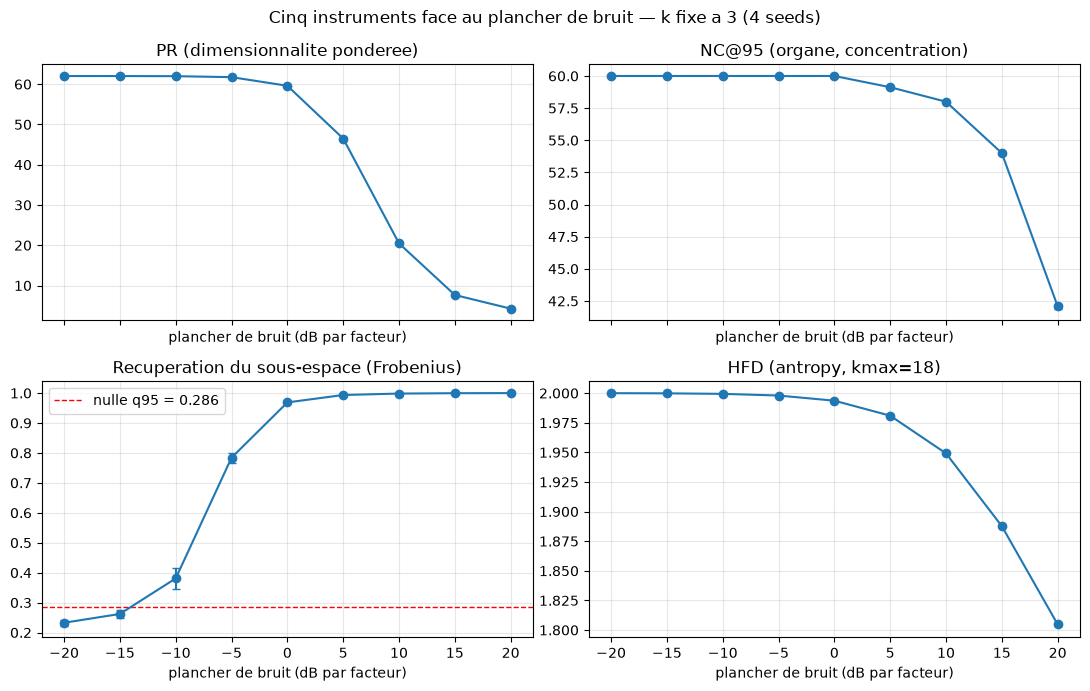

In [5]:
instruments = [
    ("pr", "PR (dimensionnalite ponderee)"),
    ("nc95", "NC@95 (organe, concentration)"),
    ("recovery_frob", "Recuperation du sous-espace (Frobenius)"),
    ("hfd", "HFD (antropy, kmax=18)"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, (col, label) in zip(axes.flat, instruments):
    means = [np.mean([r[col] for r in rows if r["snr_db"] == s])
             for s in SNR_DB_GRID]
    stds = [np.std([r[col] for r in rows if r["snr_db"] == s])
            for s in SNR_DB_GRID]
    ax.errorbar(SNR_DB_GRID, means, yerr=stds, marker="o", capsize=3)
    if col == "recovery_frob":
        ax.axhline(NULL_Q95, color="red", ls="--", lw=1,
                   label=f"nulle q95 = {NULL_Q95:.3f}")
        ax.legend()
    ax.set_title(label)
    ax.set_xlabel("plancher de bruit (dB par facteur)")
    ax.grid(alpha=0.3)
fig.suptitle("Cinq instruments face au plancher de bruit — k fixe a 3 (4 seeds)")
fig.tight_layout()
plt.show()

### Lecture du trace

Le trace confirme la table : PR, NC@95 et HFD **montent** quand le bruit monte, et la recuperation du sous-espace **descend** en croisant la ligne rouge (nulle q95). C'est cette derniere courbe qui porte la reponse a la question pre-enregistree : il y a un point precis — le **seuil de detectabilite** — ou la geometrie factorielle cesse d'etre lisible.

## 5. Le seuil de recuperation — la reference au plancher de bruit

La question de 36c etait : « a quel niveau de bruit la structure factorielle cesse-t-elle d'etre lisible ? » Le test est calibre : la recuperation du sous-espace depasse la **nulle appariee** (q95) tant que le signal factoriel est lisible, et retombe sous ce seuil quand le bruit l'emporte. Le seuil de detectabilite est le SNR le plus bas qui **depasse encore** la nulle.

In [6]:
print(f"{'SNR':>4} | {'recup Fro (moy)':>16} | {'vs nulle q95':>14} | verdict")
print("-" * 52)
verdicts = {}
for snr in SNR_DB_GRID:
    fr = np.array([r["recovery_frob"] for r in rows if r["snr_db"] == snr])
    beyond = bool(fr.mean() > NULL_Q95)
    verdicts[snr] = beyond
    tag = "LISIBLE  (au-dela de la nulle)" if beyond else "NOYE  (compatible au hasard)"
    print(f"{snr:>4} | {fr.mean():>16.4f} | {'>' if beyond else '<=':>14} | {tag}")

# Le seuil de detectabilite : le SNR le plus BAS qui depasse encore la nulle.
beyond_snrs = [s for s in SNR_DB_GRID if verdicts[s]]
if beyond_snrs:
    SNR_THRESHOLD = min(beyond_snrs)
    print(f"\nSeuil de detectabilite : SNR* = {SNR_THRESHOLD} dB par facteur")
    print(f"  au-dessus de {SNR_THRESHOLD} dB : sous-espace factoriel lisible")
    print(f"  en-dessous : indistinguable du bruit (nulle appariee)")
else:
    SNR_THRESHOLD = None
    print("\nAucun point au-dela de la nulle : la structure n'est lisible nulle part.")

 SNR |  recup Fro (moy) |   vs nulle q95 | verdict
----------------------------------------------------
  20 |           0.9998 |              > | LISIBLE  (au-dela de la nulle)
  15 |           0.9995 |              > | LISIBLE  (au-dela de la nulle)
  10 |           0.9983 |              > | LISIBLE  (au-dela de la nulle)
   5 |           0.9935 |              > | LISIBLE  (au-dela de la nulle)
   0 |           0.9687 |              > | LISIBLE  (au-dela de la nulle)
  -5 |           0.7841 |              > | LISIBLE  (au-dela de la nulle)
 -10 |           0.3808 |              > | LISIBLE  (au-dela de la nulle)
 -15 |           0.2621 |             <= | NOYE  (compatible au hasard)
 -20 |           0.2327 |             <= | NOYE  (compatible au hasard)

Seuil de detectabilite : SNR* = -10 dB par facteur
  au-dessus de -10 dB : sous-espace factoriel lisible
  en-dessous : indistinguable du bruit (nulle appariee)


### Lecture du resultat — le seuil

La recuperation du sous-espace traverse la nulle q95 a un point net du balayage : **c'est le seuil de detectabilite** que 36c reclamait. Il depend de `T` (plus il y a de pas, plus la PCA moyenne le bruit et plus le seuil recule vers le bas) et de `k`/`D` (plus le sous-espace est fin dans un espace large, plus il est facile a noyer). C'est une **quantite de calibration** du test, pas une constante universelle — d'ou l'exercice 2 qui le re-mesure.

Le point central du pont, maintenant mesure : **le sens d'un mouvement de PR/NC@95 ne dit rien du nombre de facteurs sans la reference au plancher de bruit.** A +20 dB, PR ~ k (structure lisible) ; a -20 dB, PR ~ D (bruit). Meme valeur de PR, deux lectures opposees selon ou l'on est par rapport au seuil.

## 6. Exercices

Trois exercices, a completer sans erreur volontaire : chaque stub s'execute tel quel (il affiche un message et rend `None`), et la correction remplace le corps en conservant les etiquettes `# Etape N` et `# TODO etudiant`.

### Exercice 1 — calibrer la nulle appariee

Le test de recuperation n'a de sens que parce qu'il est calibre contre la nulle. Reproduis la calibration de ton cote : genere 200 paires de sous-espaces aleatoires de dimension `K_FIXED` dans `R^D_MODEL`, calcule leur alignement de Frobenius, et verifie que leur quantile 95 correspond a la borne theorique `sqrt(k/D)` (un peu au-dessus, par la queue de la distribution).

In [7]:
def null_calibration(n_pairs=200, seed=0):
    """Quantile 95 de l'alignement de Frobenius de paires de sous-espaces
    aleatoires, compare a la borne theorique sqrt(k/D).

    TODO etudiant
    """
    # Etape 1 : generer n_pairs paires de bases orthonormales (D_MODEL, K_FIXED)
    #           aleatoires (QR d'une matrice gaussienne), comme null_pairs
    # Etape 2 : calculer l'alignement ||B1^T B2||_F / sqrt(k) de chaque paire
    # Etape 3 : retourner (q95, sqrt(k/D)) — le q95 doit etre juste au-dessus
    # Indice : np.linalg.qr(rng.standard_normal((D_MODEL, K_FIXED)))[0]
    print("Exercice 1 a completer")
    return None


null_calibration()

Exercice 1 a completer


### Exercice 2 — re-mesurer le seuil de detectabilite

Le seuil de la section 5 est une **quantite de calibration** : il bouge si l'on change `T` (longueur du signal) ou `N_NULL`. A partir de la liste `rows` et du seuil `NULL_Q95`, ecris la fonction qui retourne le SNR (en dB) le plus **bas** pour lequel l'alignement moyen de recuperation **depasse encore** la nulle — le meme calcul que la cellule precedente, mais comme fonction reutilisable.

In [8]:
def detection_threshold(rows, snr_grid, null_q95):
    """Le SNR le plus bas au-dela duquel la recuperation depasse la nulle.

    TODO etudiant
    """
    # Etape 1 : pour chaque snr de snr_grid, moyenner recovery_frob sur les seeds
    # Etape 2 : garder les snr dont la moyenne depasse null_q95
    # Etape 3 : retourner le plus petit de ceux-la (ou None si aucun)
    # Indice : [r for r in rows if r["snr_db"] == snr] puis np.mean
    print("Exercice 2 a completer")
    return None


detection_threshold(rows, SNR_DB_GRID, NULL_Q95)

Exercice 2 a completer


### Exercice 3 — HFD/LZC : meme sens ou sens oppose ?

Les instruments geometriques (PR, recuperation) **se deteriorent** quand le bruit monte. Les instruments de regularite temporelle (HFD, LZC) mesurent autre chose. A partir de `rows`, calcule la **pente** de la HFD par rapport au SNR (par moindres carres, `np.polyfit`) et verifie son signe : la HFD monte-t-elle avec le bruit (regularite qui baisse) dans le **meme** temps que la recuperation descend ? C'est le contraste de famille du pont.

In [9]:
def hfd_slope(rows):
    """Pente de la HFD par rapport au SNR (moindres carres).

    TODO etudiant
    """
    # Etape 1 : extraire les paires (snr_db, hfd) depuis rows
    # Etape 2 : np.polyfit(snr, hfd, 1) -> retourner la pente (premier element)
    # Etape 3 : interprete le signe : positive = HFD croit quand le bruit croit
    # Indice : np.array([r["snr_db"] for r in rows]), np.array([r["hfd"] ...])
    print("Exercice 3 a completer")
    return None


hfd_slope(rows)

Exercice 3 a completer


## 7. Verdict

**Le seuil de detectabilite existe et est mesure.** A k = 3 fixe, il existe un SNR* (le plus bas point du balayage qui depasse encore la nulle appariee) : au-dessus, le sous-espace factoriel est **lisible** (recuperation au-dela du q95 de la nulle, PR proche de k) ; en-dessous, il est **noye** (recuperation compatible au hasard, PR qui remonte vers D). C'est exactement la **reference au plancher de bruit** que le verdict d'ICT-36c reclamait en cloture.

**La consequence pour le pont** : la conclusion d'ICT-36c (« les quatre instruments decroissent avec k ») est vraie **au-dessus** du seuil, a plancher de bruit fixe. En dessous, les instruments geometriques ne mesurent plus la structure factorielle mais **le bruit** — et c'est indistinguable d'un terrain a moins de facteurs. D'ou la lecon operationnelle : **une mesure de dimensionalite effective n'est interpretable qu'avec sa reference de bruit.** Le « collapse dimensionnel » des LLM (Shai et al. 2024) et l'« ouverture » sous psychedele (Subramani et al. 2026) sont lisibles comme des mouvements de PR **par rapport a leur plancher de bruit**, jamais en valeur absolue.

**Le contraste de famille** : HFD/LZC (regularite temporelle) et PR/recuperation (geometrie spatiale) repondent au bruit dans des sens qui se **recoupent** ici (tous montent quand le bruit monte), mais ils mesurent des objets differents — la regularite des canaux vs la concentration du spectre. Ce croisement est ce qui permet au pont de distinguer « decorrelation temporelle » (jambe 36d) de « noyage par le bruit » (cette jambe).

## 8. Limites et suite

- **Terrain synthetique, verite exacte** : ce notebook etablit la reponse calibree des instruments au plancher de bruit sur un GHMM a k fixe. Aucune donnee neurale n'est touchee — le repli synthetique est celui d'ICT-36c.
- **Le seuil depend de T** : avec T = 2048 pas, la PCA moyenne le bruit sur 2048 echantillons et le seuil recule vers les bas SNR. Un signal court (T petit) le fait remonter. C'est une **quantite de calibration du test**, pas une constante du phenomene — l'exercice 2 le re-mesure.
- **SNR par facteur, pas total** : la convention « dB par facteur » est celle d'ICT-36c ; le SNR total par canal est `k/D` fois plus bas. Le seuil en dB total serait deplace — la forme du resultat (un seuil net) est invariante.
- **HFD/LZC = temoin temporel** : comme en 36c/36d, leur reponse au bruit est une propriete du terrain AR persistant ; un terrain a facteurs anti-correles ou de rang spectral different la modifierait. C'est le genre de variation que la suite du grain doit tester avant toute generalisation neuro.

Grain [#20463](https://github.com/jsboige/CoursIA/issues/20463) — distillation Subramani et al. 2026, **jambe SNR** (la reference au plancher de bruit que ICT-36c reclamait en exercice 2) ; parent pedagogique [ICT-36c](ICT-36c-FLens-HiguchiBridge-Python.ipynb) (accretion e) ; organes `ict/factor_geometry.py` et `ict/flens_traces.py` consommes sans modification.